# Heterogeneous Agent Consumption

## Alcance y pregunta

¿El riesgo de ingreso cambia el ahorro precautorio y la propensión marginal a consumir?

**Laboratorio estructural sintético.** La ampliación semanal sustituye el baseline OLS genérico por un experimento del mecanismo anunciado. No contiene estimaciones de datos de Colombia ni evidencia de desempeño productivo.

## Modelo y mecanismo

$$\max_{0\leq c\leq w}u(c)+\beta E[u((1+r)(w-c)+y)]$$

Modelo de dos períodos con utilidad logarítmica y dos estados de ingreso equiprobables. Se resuelve consumo inicial por optimización escalar acotada y se calcula MPC mediante diferencia central de riqueza. La comparación mantiene fijo el ingreso esperado.

### Supuestos de identificación

Mercado incompleto con un activo seguro; no endeudamiento; ingreso futuro positivo; dos períodos.

La verdad del DGP es conocida por construcción. Recuperar esa verdad comprueba implementación y diseño; no establece que el mecanismo describa una población observada.

## Configuración reproducible

Se usan NumPy, SciPy, Pandas y Matplotlib del entorno de investigación del repositorio. La semilla es fija, todos los cálculos se ejecutan desde los inputs y ninguna celda lee resultados precomputados. OLS incluye intercepto salvo fórmulas que lo excluyen explícitamente.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
plt.rcParams.update({'font.size': 11, 'axes.spines.top': False,
                     'axes.spines.right': False, 'figure.dpi': 110})
COLORS=['#245C83','#B56A20','#637843']
SEED=20261018
REPLICATIONS=40

def ols_fit(y, regressors):
    """Intercept included; QR/SVD-backed least squares, no matrix inversion."""
    X=np.column_stack([np.ones(len(y)),regressors])
    coefficients,_,rank,_=np.linalg.lstsq(X,y,rcond=None)
    if rank<X.shape[1]: raise ValueError('Diseño sin rango completo')
    return coefficients,y-X@coefficients

def ar_process(rng,n,rho):
    if abs(rho)>=1: raise ValueError('Se requiere AR estacionario')
    draws=rng.normal(size=n+200); x=np.zeros(n+200)
    for t in range(1,len(x)): x[t]=rho*x[t-1]+draws[t]
    return x[200:]


## Datos y experimento

Modelo de dos períodos con utilidad logarítmica y dos estados de ingreso equiprobables. Se resuelve consumo inicial por optimización escalar acotada y se calcula MPC mediante diferencia central de riqueza. La comparación mantiene fijo el ingreso esperado.

El siguiente código define el DGP o problema de equilibrio y sus comparadores. Las restricciones, oráculos analíticos y condiciones de factibilidad que corresponden al mecanismo se comprueban dentro de la función. Las cantidades monetarias se expresan en unidades sintéticas.

In [2]:
def experiment(rng,level,n=500):
    from scipy.optimize import minimize_scalar
    beta=.96;rate=.03; wealth=2.; future=np.array([1-level,1+level])
    def optimum(w):
        def objective(c):return -np.log(c)-beta*np.mean(np.log((1+rate)*(w-c)+future))
        out=minimize_scalar(objective,bounds=(1e-8,w),method='bounded',options={'xatol':1e-10})
        assert out.success
        return out.x
    consumption=optimum(wealth);h=.001;mpc=(optimum(wealth+h)-optimum(wealth-h))/(2*h)
    return {'Consumo inicial':consumption,'Ahorro inicial':wealth-consumption,'MPC local':mpc},(future,(1+rate)*(wealth-consumption)+future)


### Un escenario reproducible

Cada métrica conserva su denominador y unidad conceptual; no se mezclan conteos, probabilidades y costos en un mismo eje. La tabla muestra el caso central de la malla, antes de resumir réplicas.

In [3]:
GRID=[0, 0.1, 0.3, 0.5, 0.8]
METRICS=['Consumo inicial', 'Ahorro inicial', 'MPC local']
central=GRID[len(GRID)//2]
example,diagnostic=experiment(np.random.default_rng(SEED),central)
display(pd.DataFrame({'Métrica':list(example),'Valor':list(example.values())}))
print('Escenario central:',central,'; semilla:',SEED)


Escenario central: 0.3 ; semilla: 20261018


,Métrica,Valor
0,Consumo inicial,1.486591
1,Ahorro inicial,0.513409
2,MPC local,0.519630


## Sensibilidad y variación entre réplicas

**Eje:** Dispersión del ingreso futuro.

Se conservan 40 réplicas por escenario. Se reinicia la misma secuencia de semillas para cada nivel: las comparaciones entre niveles comparten innovaciones cuando la dimensión del DGP lo permite. En mecanismos deterministas los cuantiles coinciden; esto no representa una incertidumbre estimada de parámetros. No se descartan resultados desfavorables.

In [4]:
records=[]
for level in GRID:
    for replicate in range(REPLICATIONS):
        metrics,_=experiment(np.random.default_rng(SEED+replicate),level)
        if set(metrics)!=set(METRICS): raise AssertionError('Métricas inconsistentes')
        for name,value in metrics.items():
            if not np.isfinite(value):raise ArithmeticError(f'Resultado no finito: {name}')
            records.append({'nivel':level,'replica':replicate,'metrica':name,'valor':float(value)})
raw=pd.DataFrame(records)
summary=raw.groupby(['nivel','metrica'],sort=False).valor.agg(
    media='mean',mediana='median',sd_replicas='std',
    q025=lambda x:x.quantile(.025),q975=lambda x:x.quantile(.975),n='size').reset_index()
summary['se_media_mc']=summary.sd_replicas/np.sqrt(summary.n)
display(summary.round(5))


,nivel,metrica,media,mediana,sd_replicas,q025,q975,n,se_media_mc
0,0.0,Consumo inicial,1.51575,1.51575,0.0,1.51575,1.51575,40,0.0
1,0.0,Ahorro inicial,0.48425,0.48425,0.0,0.48425,0.48425,40,0.0
2,0.0,MPC local,0.51019,0.51019,0.0,0.51019,0.51019,40,0.0
3,0.1,Consumo inicial,1.51245,1.51245,0.0,1.51245,1.51245,40,0.0
4,0.1,Ahorro inicial,0.48755,0.48755,0.0,0.48755,0.48755,40,0.0
5,0.1,MPC local,0.51131,0.51131,0.0,0.51131,0.51131,40,0.0
6,0.3,Consumo inicial,1.48659,1.48659,0.0,1.48659,1.48659,40,0.0
7,0.3,Ahorro inicial,0.51341,0.51341,0.0,0.51341,0.51341,40,0.0
8,0.3,MPC local,0.51963,0.51963,0.0,0.51963,0.51963,40,0.0
9,0.5,Consumo inicial,1.43735,1.43735,0.0,1.43735,1.43735,40,0.0


### Qué muestran los intervalos

Las bandas de la figura son cuantiles 2.5–97.5% entre realizaciones del DGP, **no intervalos de confianza de un estimador en una sola muestra**. `se_media_mc` mide únicamente el error Monte Carlo de la media en este conjunto de réplicas; no mide incertidumbre económica ni corrige especificación. Se informa media y mediana para detectar asimetría, especialmente bajo identificación débil.

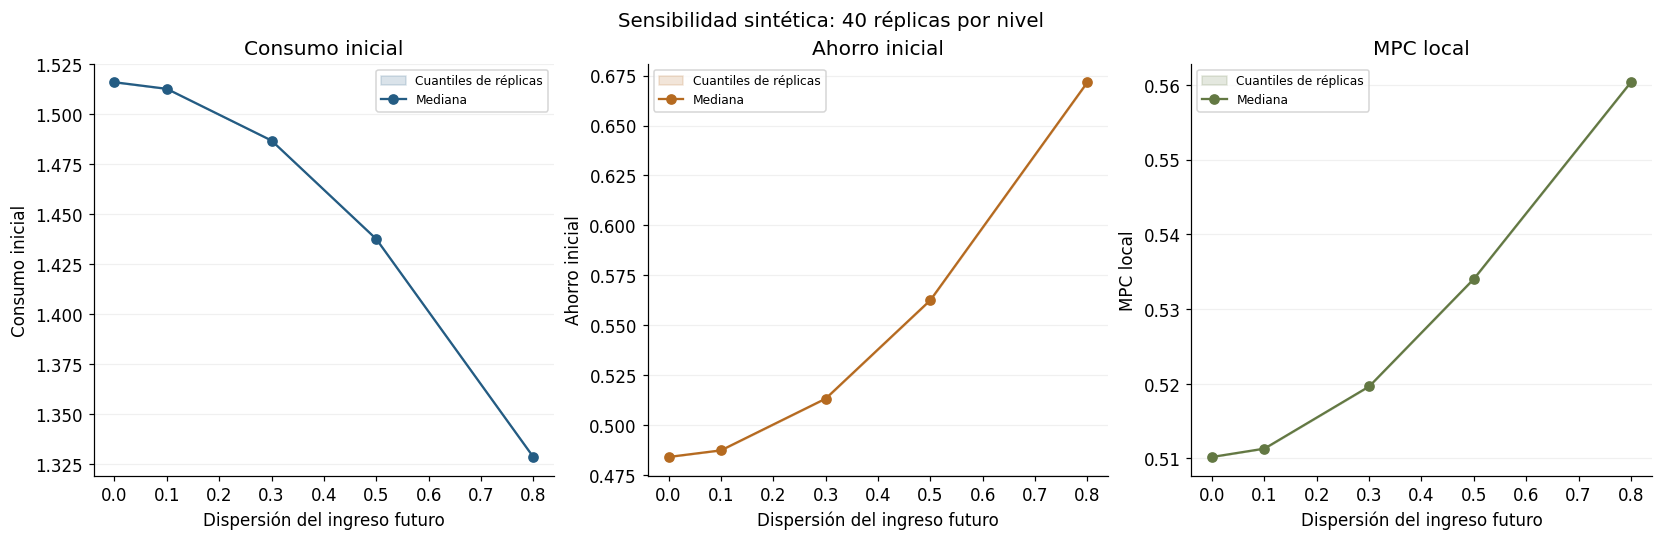

In [5]:
import textwrap
fig,axes=plt.subplots(1,len(METRICS),figsize=(15,4.8),layout='constrained')
for index,(ax,name) in enumerate(zip(np.atleast_1d(axes),METRICS)):
    group=summary[summary.metrica==name].sort_values('nivel')
    ax.fill_between(group.nivel,group.q025,group.q975,color=COLORS[index%3],alpha=.17,label='Cuantiles de réplicas')
    ax.plot(group.nivel,group.mediana,'o-',color=COLORS[index%3],label='Mediana')
    ax.set(title='\n'.join(textwrap.wrap(name,25)),xlabel='\n'.join(textwrap.wrap('Dispersión del ingreso futuro',30)),ylabel=name)
    ax.grid(axis='y',alpha=.18); ax.legend(fontsize=8)
fig.suptitle('Sensibilidad sintética: 40 réplicas por nivel',fontsize=13)
plt.show()


## Lectura de resultados ejecutados

El contraste siguiente se calcula con las salidas de la ejecución, sin fijar de antemano el signo de la conclusión. Debe interpretarse junto con los supuestos y la variación entre réplicas.

In [6]:
for name in METRICS:
    group=summary[summary.metrica==name].sort_values('nivel')
    first,last=group.iloc[0],group.iloc[-1]
    print(f"{name}: mediana {first['mediana']:.6g} en nivel {first['nivel']:g}; "
          f"{last['mediana']:.6g} en nivel {last['nivel']:g}.")
    print(f"  Último escenario: cuantiles [{last['q025']:.6g}, {last['q975']:.6g}], "
          f"media {last['media']:.6g}, error MC de la media {last['se_media_mc']:.3g}.")


Consumo inicial: mediana 1.51575 en nivel 0; 1.32836 en nivel 0.8.
  Último escenario: cuantiles [1.32836, 1.32836], media 1.32836, error MC de la media 0.
Ahorro inicial: mediana 0.484248 en nivel 0; 0.671636 en nivel 0.8.
  Último escenario: cuantiles [0.671636, 0.671636], media 0.671636, error MC de la media 0.
MPC local: mediana 0.510193 en nivel 0; 0.560361 en nivel 0.8.
  Último escenario: cuantiles [0.560361, 0.560361], media 0.560361, error MC de la media 0.


## Comprobaciones y controles

La reproducibilidad exige que la misma semilla reconstruya las mismas métricas. Los asserts estructurales de la función no dependen de que un estimador estocástico gane a otro en esta realización. Los conteos se reconcilian para no perder réplicas silenciosamente.

In [7]:
repeated,_=experiment(np.random.default_rng(SEED),central)
assert all(np.isclose(example[k],repeated[k],rtol=0,atol=1e-12) for k in METRICS)
assert len(raw)==len(GRID)*REPLICATIONS*len(METRICS)
assert summary.n.eq(REPLICATIONS).all()
assert (summary.q025<=summary.mediana+1e-12).all()
assert (summary.mediana<=summary.q975+1e-12).all()
print('Semilla, finitud, cuantiles y totalidad de réplicas: correctos.')


Semilla, finitud, cuantiles y totalidad de réplicas: correctos.


## Límites y siguiente contraste

El modelo no es una solución de equilibrio HANK ni una calibración del consumo colombiano. La restricción puede dominar la respuesta.

Antes de incorporar datos observados se debe fijar unidad de análisis, fecha de disponibilidad, reglas de exclusión y población de evaluación. La ampliación demuestra un mecanismo acotado; no convierte el proyecto en modelo validado externamente.

## Trazabilidad

Desarrollo semanal sobre `865c326`, revisión del 18-10-2026 UTC (noche del 17-10 en Colombia). El historial Git conserva el baseline genérico anterior. Todos los datos nuevos se regeneran desde la función `experiment`; las salidas del notebook se guardan después de ejecutar sus celdas de principio a fin.